# BFSBL example (host, `model_jax`)

Two finite sources, binary lens. Photometry and astrometry from `bagle.model_jax` (BFSBL lives only there), compared to the matching point-source (`BSBL`) model.

The geometry is a close binary with a small impact parameter so the primary source crosses a caustic.

**Units (phot+astrom):** `sepL`, `sepS` in mas; `radiusS_*` in arcsec;
$\rho = r_S \times 10^3 / \theta_E$.

Milestone (e), after (d2).

In [1]:
%matplotlib inline
from bagle import model_jax as model
import numpy as np
import matplotlib.pyplot as plt

<frozen importlib._bootstrap>:491: FutureWarning: pybind11-bound class 'celerite.solver.CholeskySolver' is using an old-style placement-new '__setstate__' which has been deprecated. See the upgrade guide in pybind11's docs. This message is only visible when compiled in debug mode.


## Phot+astrom parameters (caustic-crossing)

| Param | Value | Units |
|---|---|---|
| $m_{Lp}, m_{Ls}$ | 0.5, 0.5 | $M_\odot$ |
| $t_0$ | 57000 | MJD |
| $\beta$ | 0.02 | mas |
| $sep_L$ | 0.8 | mas |
| $\alpha_L$ | 0 | deg |
| $sep_S$ | 0.15 | mas |
| $\alpha_S$ | 20 | deg |
| $d_L, d_S$ | 4000, 8000 | pc |
| $radiusS_{pri}, radiusS_{sec}$ | $1\times10^{-4}$, $6\times10^{-5}$ | arcsec |
| $b_{sff}$ | 1.0 | |
| $mag_{src,pri}$, $mag_{src,sec}$ | 18.0, 18.6 | |

In [2]:
shared = dict(
    mLp=0.5, mLs=0.5, t0=57000.0, xS0_E=[0.0], xS0_N=[0.0],
    beta=0.02, muL_E=0.0, muL_N=0.0, muS_E=5.0, muS_N=0.0,
    dL=4000.0, dS=8000.0, sepL=0.8, alphaL=0.0, sepS=0.15, alphaS=20.0,
    mag_src_pri=[18.0], mag_src_sec=[18.6], b_sff=[1.0], dmag_Lp_Ls=[20.0],
)
bfsbl = model.BFSBL_PhotAstrom_noPar_Param1(
    **shared, radiusS_pri=1e-4, radiusS_sec=6e-5,
)
bfsbl.n_outline = 40
bsbl = model.BSBL_PhotAstrom_noPar_Param1(**shared)
t = np.linspace(bfsbl.t0 - 0.6 * bfsbl.tE, bfsbl.t0 + 0.6 * bfsbl.tE, 50)
rho_pri = bfsbl.radiusS_pri * 1e3 / bfsbl.thetaE_amp
rho_sec = bfsbl.radiusS_sec * 1e3 / bfsbl.thetaE_amp
print(f'thetaE = {bfsbl.thetaE_amp:.3f} mas, u0 = {bfsbl.u0_amp:.3f}')
print(f'rho_pri = {rho_pri:.3f}, rho_sec = {rho_sec:.3f}, tE = {bfsbl.tE:.1f} d')

thetaE = 1.009 mas, u0 = 0.020
rho_pri = 0.099, rho_sec = 0.059, tE = 73.7 d


findfont: Failed to find font weight normal, now using 500.


findfont: Failed to find font weight normal, now using 500.


findfont: Failed to find font weight normal, now using 500.


Text(0.5, 1.0, 'Finite-source residual')

findfont: Failed to find font weight normal, now using 500.


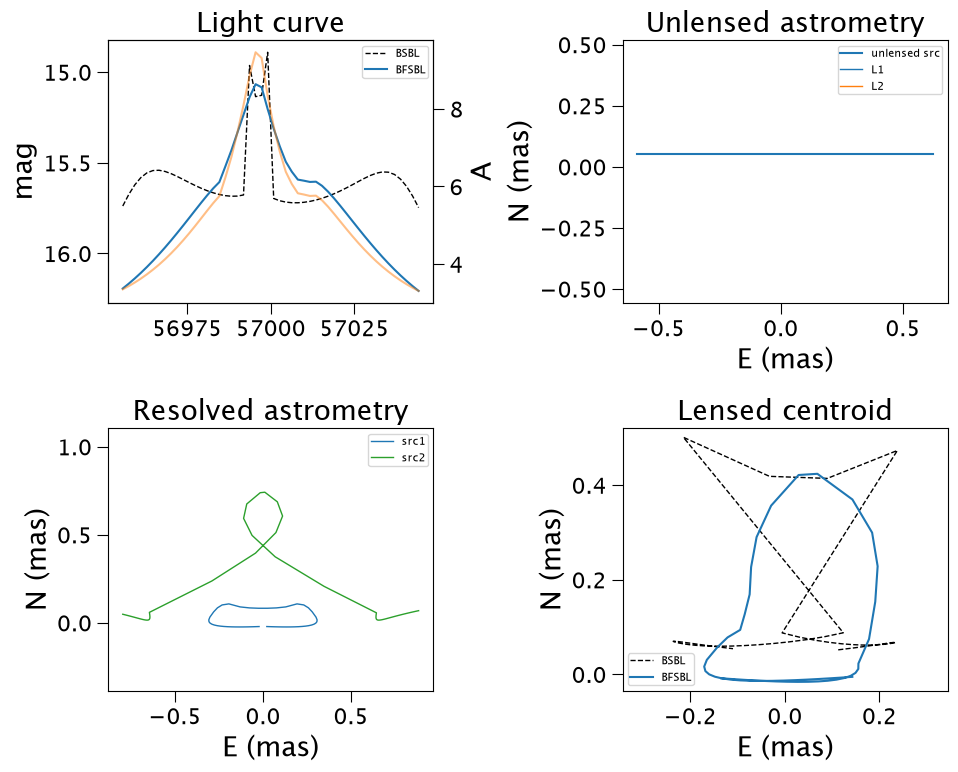

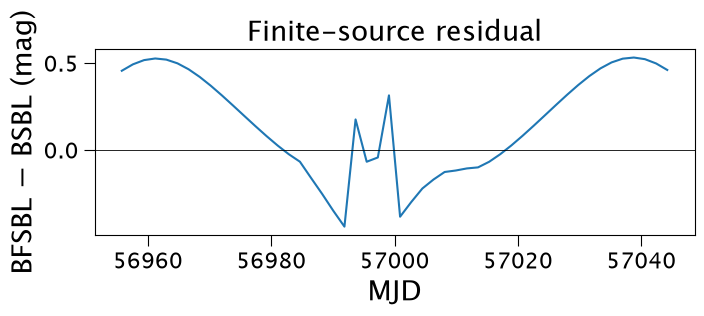

In [3]:
mag_fs = np.asarray(bfsbl.get_photometry(t))
mag_ps = np.asarray(bsbl.get_photometry(t))
amp_fs = np.asarray(bfsbl.get_amplification(t))
xU = np.asarray(bfsbl.get_astrometry_unlensed(t)) * 1e3
xL = np.asarray(bfsbl.get_resolved_lens_astrometry(t)) * 1e3
xR = np.asarray(bfsbl.get_resolved_astrometry(t)) * 1e3
xA_fs = np.asarray(bfsbl.get_astrometry(t)) * 1e3
xA_ps = np.asarray(bsbl.get_astrometry(t)) * 1e3

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

ax = axes[0, 0]
ax.plot(t, mag_ps, 'k--', lw=1, label='BSBL')
ax.plot(t, mag_fs, 'C0', lw=1.5, label='BFSBL')
ax.set_ylabel('mag')
ax.invert_yaxis()
ax.legend(fontsize=8)
ax.set_title('Light curve')
ax2 = ax.twinx()
ax2.plot(t, amp_fs, 'C1', alpha=0.5)
ax2.set_ylabel('A')

ax = axes[0, 1]
ax.plot(xU[:, 0], xU[:, 1], 'C0', lw=1.5, label='unlensed src')
for k, lab in enumerate(('L1', 'L2')):
    ax.plot(xL[:, k, 0], xL[:, k, 1], lw=1, label=lab)
ax.set_xlabel('E (mas)')
ax.set_ylabel('N (mas)')
ax.set_aspect('equal', adjustable='datalim')
ax.legend(fontsize=8)
ax.set_title('Unlensed astrometry')

ax = axes[1, 0]
colors = ('C0', 'C2')
for s in range(xR.shape[1]):
    track = xR[:, s, 0]
    ok = np.isfinite(track).all(axis=1)
    ax.plot(track[ok, 0], track[ok, 1], color=colors[s], lw=1,
            label=f'src{s + 1}')
ax.set_xlabel('E (mas)')
ax.set_ylabel('N (mas)')
ax.set_aspect('equal', adjustable='datalim')
ax.legend(fontsize=8)
ax.set_title('Resolved astrometry')

ax = axes[1, 1]
ax.plot(xA_ps[:, 0], xA_ps[:, 1], 'k--', lw=1, label='BSBL')
ax.plot(xA_fs[:, 0], xA_fs[:, 1], 'C0', lw=1.5, label='BFSBL')
ax.set_xlabel('E (mas)')
ax.set_ylabel('N (mas)')
ax.set_aspect('equal', adjustable='datalim')
ax.legend(fontsize=8)
ax.set_title('Lensed centroid')

fig.tight_layout()

fig, ax = plt.subplots(figsize=(8, 2.4))
ax.plot(t, mag_fs - mag_ps, 'C0')
ax.axhline(0.0, color='k', lw=0.6)
ax.set_xlabel('MJD')
ax.set_ylabel('BFSBL $-$ BSBL (mag)')
ax.set_title('Finite-source residual')